# **Project Name** - **Hotel Recommendation**
##### **Project Type** - Recommendation system
##### **Contribution** - Team (3 members)

# **Problem Statement**
**Voyage Analytics** is a travel-tech capstone built on three datasets - *users*, *flights* and *hotels* - with a dual goal:
(1) use them to make better travel decisions with machine learning, and (2) learn MLOps by productionising those models
(REST API -> Docker -> Kubernetes -> Airflow -> Jenkins CI/CD -> MLflow -> Streamlit).

**Business objective:** suggest hotels to users based on their preferences and booking history (Objective 9), and expose the results in a Streamlit app.

## ***1. Data & structure***

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from voyage import config, data
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)

from voyage import recommender as rc
hotels, flights = data.load_hotels(), data.load_flights()
cat = hotels.groupby('name').agg(place=('place','first'), price=('price','first'), bookings=('total','size')).sort_values('bookings', ascending=False)
display(cat)
print('users:', hotels.userCode.nunique(), '| avg distinct hotels tried per user:', round(hotels.groupby('userCode').name.nunique().mean(), 2), 'of', len(cat))

,place,price,bookings
name,,,
Hotel K,Salvador (BH),263.41,5094
Hotel CB,Rio de Janeiro (RJ),165.99,5029
Hotel BD,Natal (RN),242.88,4829
Hotel AF,Sao Paulo (SP),139.10,4828
Hotel AU,Recife (PE),312.83,4467
Hotel BP,Brasilia (DF),247.62,4437
Hotel BW,Campo Grande (MS),60.39,4333
Hotel Z,Aracaju (SE),208.04,4205
Hotel A,Florianopolis (SC),313.02,3330


users: 1310 | avg distinct hotels tried per user: 7.42 of 9


Key structure: only **9 hotels**, each in **one city** with **one fixed price**, and users have tried **~7.4 of the 9** on average. So this is not a large-catalogue discovery problem; it is a *ranking* problem over a small set, plus a strong destination signal.

## ***2. Approach: hybrid recommender***

`score(h) = 0.7 x item-CF(h | user history) + 0.3 x popularity(h) + 0.5 x user's own affinity(h)` and, if the next destination is known, a large boost for the hotel in that city.
* **Item-based collaborative filtering:** cosine similarity between hotels' user-booking-count vectors.
* **Popularity:** handles cold-start users (no history).
* **Destination boost / budget filter / exclude-visited:** business rules exposed in the API.

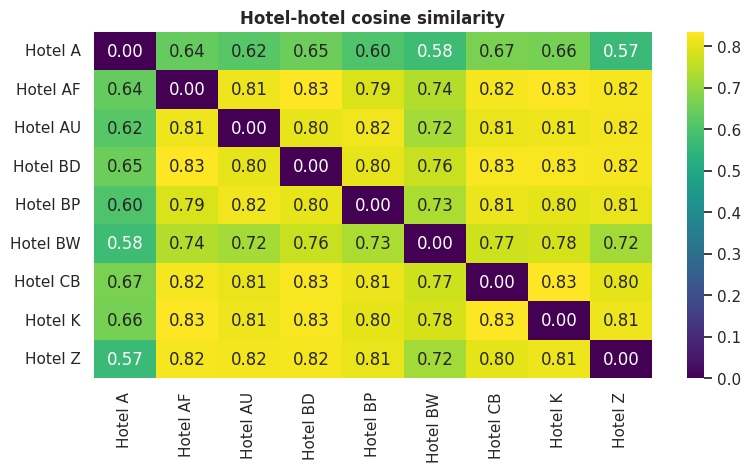

Off-diagonal similarity range: 0.567 - 0.835


In [2]:
rec = rc.HotelRecommender().fit(hotels)
sim = pd.DataFrame(rec.sim_, index=rec.hotels_, columns=rec.hotels_)
sns.heatmap(sim, annot=True, fmt='.2f', cmap='viridis'); plt.title('Hotel-hotel cosine similarity'); plt.show()
print('Off-diagonal similarity range:', round(rec.sim_[rec.sim_>0].min(), 3), '-', round(rec.sim_.max(), 3))

Hotel-hotel similarities all fall in a narrow band (**0.57-0.84**) because almost every user tried almost every hotel, so there is little difference between 'similar' and 'dissimilar' hotels. Collaborative filtering therefore has **limited discriminating power** here - an important honest limitation.

In [3]:
print('Existing user 0:'); display(pd.DataFrame(rec.recommend(0, k=3)))
print('Same user, next trip to Natal (RN):'); display(pd.DataFrame(rec.recommend(0, k=3, destination='Natal (RN)')))
print('Cold-start user, budget <= 150/night:'); display(pd.DataFrame(rec.recommend(None, k=3, max_price=150)))
print('Hotels similar to Hotel A:'); display(pd.DataFrame(rec.similar_hotels('Hotel A')))

Existing user 0:


,hotel,place,price_per_night,score
0,Hotel K,Salvador (BH),263.41,1.3340
1,Hotel BD,Natal (RN),242.88,1.1852
2,Hotel AF,Sao Paulo (SP),139.10,1.1837


Same user, next trip to Natal (RN):


,hotel,place,price_per_night,score
0,Hotel BD,Natal (RN),242.88,11.1852
1,Hotel K,Salvador (BH),263.41,1.3340
2,Hotel AF,Sao Paulo (SP),139.10,1.1837


Cold-start user, budget <= 150/night:


,hotel,place,price_per_night,score
0,Hotel AF,Sao Paulo (SP),139.10,0.9478
1,Hotel BW,Campo Grande (MS),60.39,0.8506


Hotels similar to Hotel A:


,hotel,place,similarity
0,Hotel CB,Rio de Janeiro (RJ),0.6659
1,Hotel K,Salvador (BH),0.6589
2,Hotel BD,Natal (RN),0.6473


## ***3. Offline evaluation - predict each user's most recent stay***

,hybrid,popularity,random
hit@1,0.120,0.122,0.111
hit@3,0.368,0.349,0.333
hit@5,0.612,0.598,0.556


users evaluated: 1245


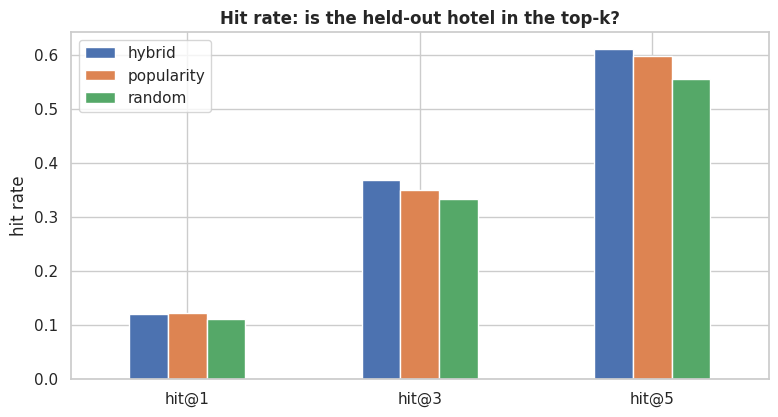

In [4]:
metrics = rc.evaluate_leave_last_out(hotels)
ev = pd.DataFrame({k: v for k, v in metrics.items() if isinstance(v, dict)}).T; display(ev.round(3)); print('users evaluated:', metrics['n_eval_users'])
ev.plot.bar(rot=0); plt.title('Hit rate: is the held-out hotel in the top-k?'); plt.ylabel('hit rate'); plt.show()

### Is the improvement over popularity real? (paired bootstrap on hit@3)

In [5]:
h = hotels.sort_values(['userCode', 'date']); n = h.groupby('userCode').size(); ok = n[n >= 4].index
last = h[h.userCode.isin(ok)].groupby('userCode').tail(1).index; tr, te = h.drop(last), h.loc[last]
r2 = rc.HotelRecommender().fit(tr); pop3 = set(r2.hotel_info_.sort_values('bookings', ascending=False).index[:3])
hy = np.array([row['name'] in [x['hotel'] for x in r2.recommend(row.userCode, k=3)] for _, row in te.iterrows()], float)
po = np.array([row['name'] in pop3 for _, row in te.iterrows()], float)
rng = np.random.default_rng(0); diffs = [(hy[i] - po[i]).mean() for i in (rng.integers(0, len(hy), len(hy)) for _ in range(2000))]
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f'hybrid hit@3 = {hy.mean():.3f}, popularity = {po.mean():.3f}, difference = {hy.mean()-po.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]')

hybrid hit@3 = 0.368, popularity = 0.349, difference = +0.018  95% CI [-0.014, +0.051]


### Interpretation
Hybrid hit@3 is only marginally above popularity and random (1/3), and the bootstrap interval for the difference includes 0 - **the gain is not statistically established**. The next hotel a user books is close to random given history in this dataset (also seen in the EDA: month, gender and previous hotel explain little).

**Where the system genuinely adds value:** when the destination is known (it is at flight-booking time), the hotel is determined by the city (city <-> hotel is 1:1), so the destination-aware mode is exact by construction; the budget filter and 'similar hotels' features are useful product functions.

## ***4. Streamlit application***
`streamlit_app/app.py` (run `make ui`) calls the deployed API and shows: flight price predictor with class comparison, hotel recommender (user / cold-start / destination / budget / exclude-visited) with score charts and the catalogue, travel-insight dashboards, the gender demo with a warning, and a model-metrics page.

## ***Conclusion***
A hybrid recommender is implemented, evaluated with a proper hold-out protocol against popularity and random baselines, and served through the API and dashboard. Modest offline lift is reported honestly.

### ***Hurrah! You have successfully completed the Recommendation part of the capstone!!!***